In [1]:
# =============================================================================
# Imports
# =============================================================================

import os
import glob

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

import sunpy
import sunpy.map
from sunpy.net import Fido, attrs as a
from aiapy.calibrate import (
    correct_degradation,
    register,
    update_pointing,
)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# =============================================================================
# Constants and Configuration
# =============================================================================
 
# Logarithmic temperature grid: log10(T/K) from 5.5 to 7.2 in 18 steps
LOGT = np.linspace(5.5, 7.2, 18)
 
# Temperature bin width for integration
TRESP_DLOGT = np.full(18, 0.1)
 
# Factor used to convert scaled DEM values to physical emission measure units
# (accounts for the logarithmic temperature bin width)
FACTOR = 10**LOGT * np.log(10**TRESP_DLOGT)
 
# Temperature bin edges for display (19 edges for 18 bins)
TEMP_EDGES = np.logspace(5.45, 7.25, 19)
 
# Number of Monte Carlo forward passes for uncertainty estimation
N_MC_PREDICTIONS = 100
 
# AIA wavelength channels in order (Angstroms)
AIA_WAVELENGTHS = [94, 131, 171, 193, 211, 335]
 
# File paths — update these to match your local environment
k_matrix = np.load("/k_matrix.npy")
kernel = np.expand_dims(np.expand_dims(np.transpose(k_matrix), axis=0), axis=0)

In [3]:
# =============================================================================
# Scaling Utilities
# =============================================================================
 
def em_scale(x):
    """
    Scale emission measure (EM) values for neural network input.
 
    Applies a square-root compression after clipping negative values to zero,
    normalised by 1e19 to bring values into a numerically convenient range.
    """
    x = np.where(x <= 0.0, 0.0, x)
    return np.sqrt(x / 1e19)
 
 
def em_unscale(x):
    """
    Invert :func:`em_scale` to recover physical emission measure values.
    """
    return 1e19 * (x * x)
 
 
def img_scale(x):
    """
    Scale AIA intensity values (DN/s) for neural network input.
 
    Applies square-root compression after clipping negative values to zero.
    """
    x = np.where(x <= 0.0, 0.0, x)
    return np.sqrt(x)
 
 
def img_unscale(x):
    """
    Invert :func:`img_scale` to recover DN/s values.
    """
    return x * x

In [4]:
# =============================================================================
# Custom Keras Layers
# =============================================================================
 
class MonteCarloDropout(layers.Dropout):
    """
    Dropout layer that remains active at inference time.
 
    Standard Keras Dropout is disabled during prediction. This subclass
    overrides that behaviour so that stochastic forward passes can be used
    for Bayesian uncertainty estimation (Gal & Ghahramani, 2016).
    """
 
    def call(self, inputs):
        # Force training=True so dropout is never bypassed
        return super().call(inputs, training=True)
 
 
class LearnableNoise(tf.keras.layers.Layer):
    """
    Spatially-resolved learnable noise map.
 
    Produces a per-pixel, per-channel standard deviation estimate for an assumed gaussian noise that is trained
    jointly with the rest of the network. A softplus activation ensures
    positivity.
 
    Parameters
    ----------
    shape : tuple
        Shape of the std map (height, width, channels), matching the
        spatial dimensions of the AIA input tiles.
    """
 
    def __init__(self, shape, **kwargs):
        super().__init__(**kwargs)
        self.shape = shape
 
    def build(self, input_shape):
        self.noise_map = self.add_weight(
            shape=self.shape,
            initializer="zeros",
            trainable=True,
            name="learnable_noise_map",
        )
 
    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        # Expand and tile across the batch dimension
        return tf.tile(
            tf.expand_dims(tf.nn.softplus(self.noise_map), axis=0),
            [batch_size, 1, 1, 1],
        )
 
 
# =============================================================================
# Loss Function
# =============================================================================
 
def gaussian_nll_loss(
    y_true: tf.Tensor,
    y_pred: tf.Tensor,
    noise_pred: tf.Tensor,
    eps: float = 1e-5,
) -> tf.Tensor:
    """
    Gaussian negative log-likelihood loss with learned standard deviation.
 
    Encourages the network to predict well-calibrated uncertainty by
    penalising both prediction error and over-confident standard deviation estimates.
 
    Parameters
    ----------
    y_true : tf.Tensor
        Ground-truth AIA images.
    y_pred : tf.Tensor
        Predicted AIA images.
    noise_pred : tf.Tensor
        Predicted (positive) standard deviation map.
    eps : float
        Small constant for numerical stability (unused but kept for API
        compatibility).
 
    Returns
    -------
    tf.Tensor
        Scalar mean NLL loss.
    """
    y_true    = tf.cast(y_true,    tf.float32)
    y_pred    = tf.cast(y_pred,    tf.float32)
    noise_pred  = tf.cast(noise_pred,  tf.float32)
 
    sq_error = tf.square(y_true - y_pred)
    nll = (sq_error / (2.0 * tf.square(noise_pred))) + 0.5 * tf.math.log(tf.square(noise_pred))
    return tf.reduce_mean(nll)

In [5]:
# =============================================================================
# Model Architecture
# =============================================================================

def build_model():
    """
    Build the Bayesian CNN for DEM inference.
 
    Architecture overview
    ---------------------
    - A 1×1 convolution maps 6 AIA channels to a 128-feature representation.
    - Monte Carlo Dropout (p=0.3) is applied after each major layer.
    - A transposed convolution upsamples spatial features.
    - A 3×3 convolution produces the 18-temperature DEM map.
    - A binary mask (supplied at training time) zeros out invalid pixels.
    - The response layer synthesises AIA images from the predicted DEM for
      the physics-informed reconstruction loss.
    - A learnable std map provides per-pixel uncertainty estimates for an assumed gaussian noise on the AIA images.
 
    Two model handles are returned:
    - ``train_model``: accepts ``[image, mask]`` inputs and outputs
      ``{output_dem, output_img}``; includes the std regularisation
      as an added loss.
    - ``test_model``: accepts only the image input and additionally outputs
      the std map ``output_std``.
 
    Parameters
    ----------
    kernel : np.ndarray
        AIA temperature-response kernel, shape (1, 1, 18, 6).
    factor : np.ndarray
        Per-temperature EM integration factor, shape (18,).
 
    Returns
    -------
    train_model : tf.keras.Model
    test_model  : tf.keras.Model
    """
    # Shared layer kwargs
    conv1x1_kwargs = {"kernel_size": 1, "kernel_regularizer": l2(1e-6)}
    conv3x3_kwargs = {"kernel_size": 3, "kernel_regularizer": l2(1e-6)}
 
    # ── Inputs ────────────────────────────────────────────────────────────────
    image_input = layers.Input((512, 512, 6),  name="image_input")
    mask_input  = layers.Input((512, 512, 18), name="mask_input")
    # ──────────────────────────────────────────────────────────────────────────
 
    x = layers.Conv2D(128, **conv1x1_kwargs,
                      activation=keras.layers.LeakyReLU(alpha=0.1))(image_input)
    x = MonteCarloDropout(0.3)(x)
 
    x = layers.Conv2DTranspose(64, kernel_size=3,
                               activation=keras.layers.LeakyReLU(alpha=0.1))(x)
    x = MonteCarloDropout(0.3)(x)

    
    # ── DEM output ────────────────────────────────────────────────────────────
    dem_unmasked = layers.Conv2D(
        18, **conv3x3_kwargs,
        activation=keras.layers.LeakyReLU(alpha=0.1),
        name="output_dem_unmasked",
    )(x)
 
    dem_masked = layers.multiply([dem_unmasked, mask_input], name="output_dem")
    # ──────────────────────────────────────────────────────────────────────────

    
    # ── Image reconstruction ─────────────────────────────────
    # Convert DEM → synthetic AIA images via the instrument response function
    unscale = layers.Lambda(lambda x: em_unscale(x)*FACTOR)(dem_unmasked)
    output_img_unscaled = layers.Lambda(lambda x: tf.nn.conv2d(x, kernel, strides=[1, 1, 1, 1], padding='SAME'))(unscale)
    output_img = layers.Lambda(lambda x: tf.sqrt(x), name="output_img")(output_img_unscaled)
 
    # ── Learnable noise (aleatoric uncertainty) ────────────────────────────
    output_std = LearnableNoise(shape=(512, 512, 6), name="output_std")(dem_unmasked)

    
    # ── Assemble models ───────────────────────────────────────────────────────
    train_model = Model(
        inputs=[image_input, mask_input],
        outputs={"output_dem": dem_masked, "output_img": output_img},
    )
    train_model.add_loss(tf.reduce_mean(output_std))
 
    test_model = Model(
        inputs=image_input,
        outputs={
            "output_dem": dem_unmasked,
            "output_img": output_img,
            "output_std": output_std,
        },
    )
 
    return train_model, test_model

In [6]:
# =============================================================================
# AIA Data Loading and Preprocessing
# =============================================================================
 
def load_and_preprocess_aia(fits_dir):
    """
    Load AIA FITS files, apply standard calibration, and return pixel data.
 
    Calibration steps applied (via aiapy):
    1. Update pointing metadata.
    2. Co-register and re-sample to a common grid (``register``).
    3. Correct for instrument degradation.
    4. Normalize for exposure time
 
    A 1-pixel zero-padding is applied to the 171 Å channel to account for
    a known size discrepancy after registration.
 
    Parameters
    ----------
    fits_dir : str
        Directory containing AIA FITS files for a single observation time.
 
    Returns
    -------
    data : np.ndarray
        Calibrated image cube, shape (n_channels, H, W).
    exposure_times : np.ndarray
        Exposure duration [s] for each channel, shape (n_channels,).
    """
    fits_files = sorted(glob.glob(os.path.join(fits_dir, "*.fits")))
    if not fits_files:
        raise FileNotFoundError(f"No FITS files found in: {fits_dir}")
 
    raw_maps = sunpy.map.Map(fits_files)
 
    # Sort channels by wavelength (ascending)
    wavelengths = [m.meta["wavelnth"] for m in raw_maps]
    sort_indices = sorted(range(len(wavelengths)), key=wavelengths.__getitem__)
    sorted_maps  = [raw_maps[i] for i in sort_indices]
 
    print(f"Loaded channels (Å): {[m.meta['wavelnth'] for m in sorted_maps]}")
 
    # Apply calibration
    calibrated_maps = []
    for m in sorted_maps:
        m = update_pointing(m)
        m = register(m)
        m = correct_degradation(m)
        calibrated_maps.append(m)
 
    # Extract pixel data; pad 171 Å channel to match other channels
    pixel_data = []
    for m in calibrated_maps:
        if m.meta["wavelnth"] == 171:
            arr = np.pad(m.data, pad_width=1, mode="constant", constant_values=0)
        else:
            arr = m.data
        pixel_data.append(arr)
 
    data = np.array(pixel_data)
    
    exposure_times = np.array([m.meta["exptime"] for m in calibrated_maps])
    exposure_corrected = np.transpose(data / exposure_times[:, np.newaxis, np.newaxis], (1, 2, 0))
    
    return exposure_corrected

In [7]:
# Monte Carlo Inference
# =============================================================================
 
def run_mc_inference(
    model: tf.keras.Model,
    input_image: np.ndarray,
    n_samples: int = N_MC_PREDICTIONS,
    device: str = "/device:CPU:0"):
    """
    Run Monte Carlo Dropout inference and aggregate stochastic predictions.

    Performs ``n_samples`` stochastic forward passes with dropout active,
    then returns the per-sample predictions so callers can compute means
    and variances.

    Parameters
    ----------
    model : tf.keras.Model
        Loaded ``test_model`` with weights.
    input_image : np.ndarray
        Input tile of shape (H, W, n_channels).
    n_samples : int
        Number of stochastic forward passes.
    device : str
        TensorFlow device string.

    Returns
    -------
    tuple
        A tuple containing:
        - ``dem_preds``: DEM predictions,  shape (n_samples, H, W, 18)
        - ``img_preds``: image predictions, shape (n_samples, H, W, 6)
    """
    if input_image.shape == (512, 512, 6):
        batch = input_image[np.newaxis]  # (1, H, W, C)
        dem_preds = []
        img_preds = []

        with tf.device(device):
            for _ in range(n_samples):
                out = model.predict(batch, verbose=0)
                dem_preds.append(em_unscale(out["output_dem"]))
                img_preds.append(img_unscale(out["output_img"]))

        return dem_preds, img_preds
    
    else:
        print(f"Input image needs to be (512, 512, 6), got {input_image.shape}")
        return None

In [ ]:
#This can take a while to run so its better to save the results and load them later
fdir='/2024-05-07/'
data_preprocessed = load_and_preprocess_aia(fdir)

#np.save('/data_preprocessed.npy', data_preprocessed)

Loaded channels (Å): [94, 131, 171, 193, 211, 335]


In [ ]:
# Selecting the flaring active region NOAA AR 13664
test_sample = img_scale(data_preprocessed[2600:2600+512,2800:2800+512,:])

_,test_model = build_model()
test_model.load_weights('/dropout_weights.h5')

dem_list,img_list = run_mc_inference(
    test_model,
    test_sample,
    n_samples=N_MC_PREDICTIONS,
    device="/device:CPU:0")


In [10]:
# Define a custom segmented colormap
def custom_colormap():
    # Define color stops and positions
    colors = [
        (1.0, 1.0, 1.0),  # White for low values
        (0.5, 0.5, 1.0),  # Purple
        (0.0, 1.0, 1.0),  # Cyan
        (0.0, 1.0, 0.0),  # Green (at 2.0)
        (1.0, 1.0, 0.0),  # Yellow
        (1.0, 0.0, 0.0),  # Red
    ]
    positions = [0.0, 0.19, 0.3, 0.5, 0.6, 1.0]

    return LinearSegmentedColormap.from_list("CustomRainbow", list(zip(positions, colors)))

modified_rainbow = custom_colormap()


In [11]:
em0 = np.mean(dem_list,0)[0,:,:,:3].sum(axis=-1)
em1 = np.mean(dem_list,0)[0,:,:,3:6].sum(axis=-1)
em2 = np.mean(dem_list,0)[0,:,:,6:9].sum(axis=-1)
em3 = np.mean(dem_list,0)[0,:,:,9:12].sum(axis=-1)
em4 = np.mean(dem_list,0)[0,:,:,12:15].sum(axis=-1)
em5 = np.mean(dem_list,0)[0,:,:,15:18].sum(axis=-1)

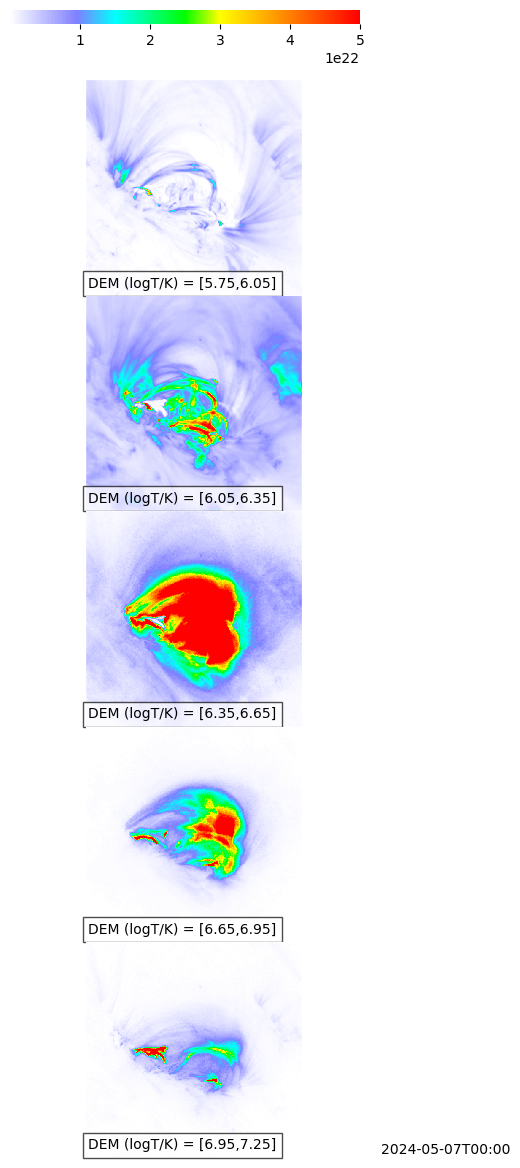

In [12]:
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(
    5, 1, figsize=(7,14),
    sharex=True, sharey=True
)

im1 = ax1.imshow(em1, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax1.text(5, 18, 'DEM (logT/K) = [5.75,6.05]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))
ax1.set_xticks([]); ax1.set_yticks([])

im2 = ax2.imshow(em2, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax2.set_xticks([]); ax2.set_yticks([])
ax2.text(5, 20, 'DEM (logT/K) = [6.05,6.35]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))

im3 = ax3.imshow(em3, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax3.set_xticks([]); ax3.set_yticks([])
ax3.text(5, 20, 'DEM (logT/K) = [6.35,6.65]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))

im4 = ax4.imshow(em4, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax4.set_xticks([]); ax4.set_yticks([])
ax4.text(5, 20, 'DEM (logT/K) = [6.65,6.95]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))

im5 = ax5.imshow(em5, cmap=modified_rainbow, vmax=5e22,origin='lower', interpolation='nearest')
ax5.text(5, 20, 'DEM (logT/K) = [6.95,7.25]',
         color="black", size=10,
         bbox=dict(facecolor='white', edgecolor='black',
                   fill=True, alpha=0.7))
ax5.text(700, 10, '2024-05-07T00:00',
         color="black", size=10,
         )
ax5.set_xticks([]); ax5.set_yticks([])

# Remove spacing between images
plt.subplots_adjust(hspace=0)

# Create dedicated colorbar axis ABOVE everything
cax = fig.add_axes([0.25, 0.92, 0.5, 0.01])  # [left, bottom, width, height]
#cax = fig.add_axes([0.2, 0.94, 0.6, 0.015])  
cbar = fig.colorbar(im1, cax=cax, orientation='horizontal',shrink=0.3)
plt.subplots_adjust(hspace=0)

# Remove ALL subplot borders (spines)
for ax in (ax1, ax2, ax3, ax4, ax5):
    for spine in ax.spines.values():
        spine.set_visible(False)

# Remove colorbar border as well
cbar.outline.set_visible(False)

plt.show()

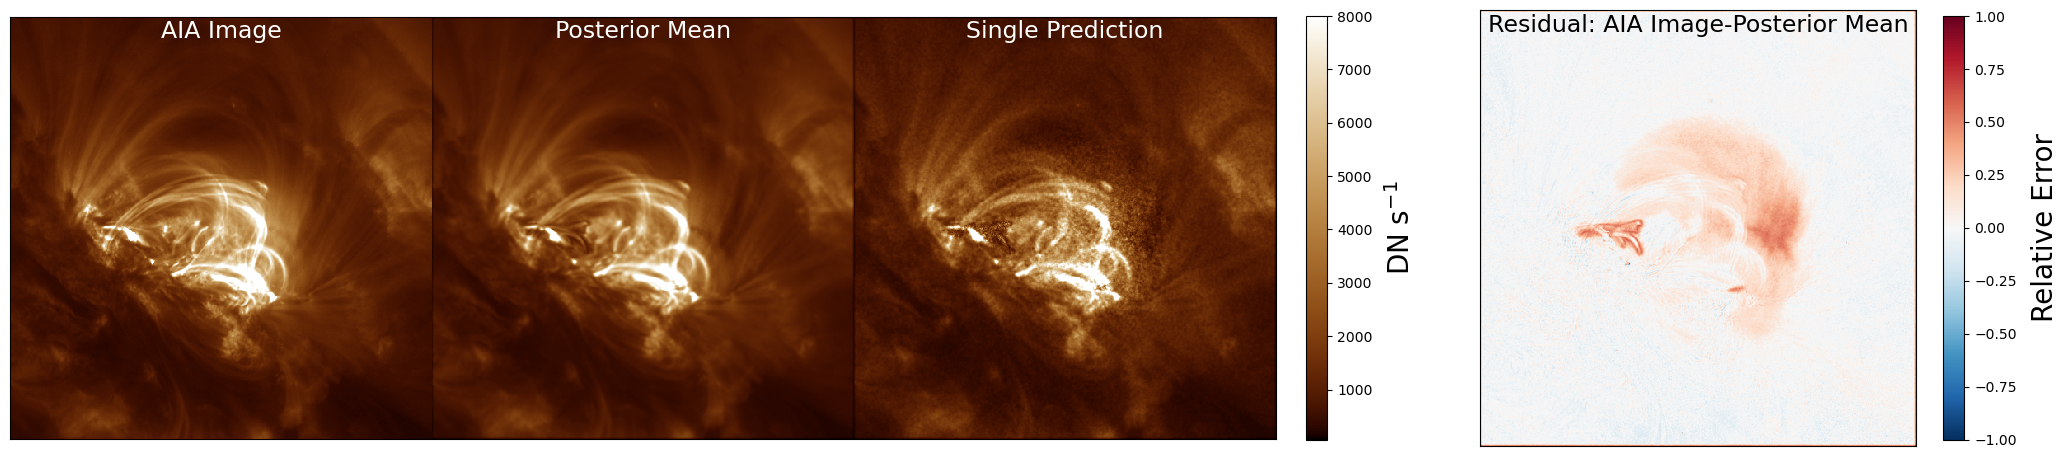

In [13]:
img1 = img_unscale(test_sample[:,:,3])
img2 = np.mean(img_list,0)[0,:,:,3]
img3 = img_list[0][0,:,:,3]
img4 = (img1 - img2)/img1

fig = plt.figure(figsize=(26,10))
gs = fig.add_gridspec(1, 4, wspace=-0.1)
ax1 = fig.add_subplot(gs[0, :3])
ax2 = fig.add_subplot(gs[0, 3])

# Left: three-panel combined
combined = np.concatenate([img1, img2, img3], axis=1)
im1 = ax1.imshow(combined,
                 cmap=matplotlib.colormaps['sdoaia193'],
                 vmax=8000,
                 interpolation='nearest', origin='lower')
ax1.set_xticks([])
ax1.set_yticks([])
cb1 = fig.colorbar(im1, ax=ax1, shrink=0.55, pad=0.02)
cb1.set_label(r'DN s$^{-1}$', size=20, labelpad=10)

h, w = img1.shape
ax1.text(w*0.5, h-26, 'AIA Image',          color='white', ha='center', size=17)
ax1.text(w*1.5, h-26, 'Posterior Mean',      color='white', ha='center', size=17)
ax1.text(w*2.5, h-26, 'Single Prediction',   color='white', ha='center', size=17)

# Right: residual map
im2 = ax2.imshow(img4,
                 cmap='RdBu_r',
                 vmin=-1, vmax=1,
                 interpolation='nearest', origin='lower')
ax2.set_xticks([])
ax2.set_yticks([])
cb2 = fig.colorbar(im2, ax=ax2, shrink=0.55)
cb2.set_label(r'Relative Error', size=20, labelpad=10)

ax2.text(w*0.5, h-26, 'Residual: AIA Image-Posterior Mean', color='black', ha='center', size=17)

plt.tight_layout()

plt.show()